# 3Di Alignment Benchmark

## Description

We compare the performance of ESM3Di against ProstT5 on the MetaVR sequence set.

We have 3 different 3Di representations of the MetaVR sequence set:
* **AF3**: 3Di generated by Foldseek based on the predicted AlphaFold3 structures of the MetaVR sequence set.
* **ProstT5**: 3Di generated by ProstT5 based on the sequences of the MetaVR sequence set.
* **ESM3Di**: 3Di generated by ESM3Di based on the sequences of the MetaVR sequence set.
* **Random Baseline**: 3Di generated at random using empirical BFVD derived 3di character frequencies.

We compile each representation into a Foldseek database and run Foldseek's `structurealign` module on a 1-vs-1 basis (aligning identical entries).

The results are represented as the **bitscore** of the alignment and **3Di sequence identity**.

The **bitscore** is a measure of the overall similarity between two aligned 3Di sequences. It rewards long, well-matching alignments while penalizing mismatches and gaps, with higher bitscores indicating more similar 3Di representations.

The **3Di sequence identity** is calculated as:

$$
\text{Identity} = \frac{\text{\# of residues with identical 3Di}}{\text{\# of residues}}
$$

In [1]:
import torch
import socket

print("Running on node:", socket.gethostname())
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device name:", torch.cuda.get_device_name(0))

Running on node: dnagpu001
GPU available: True
Device name: NVIDIA A100-PCIE-40GB MIG 3g.20gb


In [2]:
import shutil
import os

# Optional: Add local foldseek directory to PATH if installed in project folder
os.environ["PATH"] += os.pathsep + "/users/fweikert/ESM3di/foldseek/bin"

if not shutil.which("foldseek"):
    raise FileNotFoundError(
        "Foldseek binary not found in PATH. "
        "Please download the standalone binary or load the appropriate cluster module."
    )
else:
    print(f"Foldseek is ready to use at: {shutil.which('foldseek')}")

Foldseek is ready to use at: /users/fweikert/miniforge3/bin/foldseek


In [3]:
import os
import subprocess
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

# --- Configuration ---
#DATAPATH = Path("./data") # !! SET THIS BACK !!
DATAPATH = Path("/scratch/fweikert/data")  # !! SET THIS BACK !!
DATAPATH.mkdir(parents=True, exist_ok=True)

LOGS_DIR = Path("./logs")
LOGS_DIR.mkdir(exist_ok=True)

FS_DIR = DATAPATH / "foldseek"
META_DIR = DATAPATH / "metavr"
FS_DIR.mkdir(exist_ok=True)
META_DIR.mkdir(exist_ok=True)

# --- Utility Functions ---
from datetime import datetime

def run_cmd(cmd, log_path=None, silent=False):
    process = subprocess.Popen(
        cmd,
        shell=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
        env=os.environ.copy(),
    )

    log_file = open(log_path, "a", buffering=1) if log_path else None

    try:
        for line in iter(process.stdout.readline, ""):
            if not silent:
                print(line, end="", flush=True)
            if log_file:
                log_file.write(line)

        process.stdout.close()
        return_code = process.wait()

        if return_code != 0:
            raise RuntimeError(f"Command failed with exit code {return_code}: {cmd}")
    finally:
        if log_file:
            log_file.close()

def write_fasta(sequences: dict[str, str], filepath: Path):
    """Writes a dictionary of {id: sequence} to a FASTA file."""
    with open(filepath, "w") as f:
        for seq_id, seq in sequences.items():
            f.write(f">{seq_id}\n{seq}\n")

def parse_fasta(fasta_path: Path) -> dict[str, str]:
    """Reads a FASTA file into a {id: sequence} dictionary."""
    seqs, hdr = {}, None
    with open(fasta_path) as f:
        for line in f:
            line = line.strip()
            if line.startswith(">"):
                hdr = line[1:].split()[0]
                seqs[hdr] = ""
            elif hdr:
                seqs[hdr] += line
    return seqs

In [4]:
import tarfile
from curl_cffi import requests
from tqdm import tqdm

tar_path = META_DIR / "partial_download.tar.gz"
url = "https://www.meta-virome.org/Data/Downloads/IMGVR5_PC_3Dmodels.tar.gz"

max_bytes = 2 * 1024 * 1024 * 1024  # 2 GB cap
downloaded = 0

print("1. Downloading first 2 GB using browser TLS impersonation...")

response = requests.get(url, impersonate="chrome", stream=True)

if response.status_code != 200:
    print(f"Failed with status code: {response.status_code}")
else:
    # Stream download with progress bar
    with open(tar_path, "wb") as f, tqdm(
        total=max_bytes,
        unit="B",
        unit_scale=True,
        unit_divisor=1024,
        desc="Downloading 2GB sample",
    ) as pbar:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if not chunk:
                continue

            # Ensure we stop precisely at the 1 GB cap
            bytes_to_write = min(len(chunk), max_bytes - downloaded)
            f.write(chunk[:bytes_to_write])
            downloaded += bytes_to_write
            pbar.update(bytes_to_write)

            if downloaded >= max_bytes:
                break

    print(f"\nDownloaded {downloaded / (1024 * 1024):.2f} MB to {tar_path}")

    print("2. Extracting structures...")

    # Stream mode ("r|gz") reads sequentially and avoids pre-scanning the full file
    try:
        with tarfile.open(tar_path, "r|gz") as tar:
            while True:
                try:
                    member = tar.next()
                    if member is None:
                        break
                    tar.extract(member, path=META_DIR)
                except (EOFError, tarfile.TarError, OSError):
                    # Gracefully stop extraction at the truncated cutoff point
                    print("\nReached the end of the truncated 1 GB stream.")
                    break
    except Exception as e:
        print(f"\nExtraction finished with notice: {e}")

    # Clean up archive file
    if tar_path.exists():
        tar_path.unlink()

    # Count extracted files
    extracted_files = sum(1 for _ in META_DIR.glob("**/*") if _.is_file())
    print(f"3. Done! Total extracted files: {extracted_files}")

1. Downloading first 2 GB using browser TLS impersonation...



Downloaded 2048.00 MB to /scratch/fweikert/data/metavr/partial_download.tar.gz
2. Extracting structures...

Reached the end of the truncated 1 GB stream.
3. Done! Total extracted files: 70745


In [5]:
import os
import random
import shutil


def sample_structures(source_dir, output_dir, n_samples=500, seed=42):
    """Samples `n_samples` PDB/CIF files from source_dir into output_dir."""
    random.seed(seed)  # Fixed seed ensures reproducible sampling
    os.makedirs(output_dir, exist_ok=True)

    # Find all 3D structure files
    valid_exts = (".pdb", ".cif", ".ent", ".pdb.gz", ".cif.gz")
    all_files = [
        f
        for f in os.listdir(source_dir)
        if f.lower().endswith(valid_exts)
        and os.path.isfile(os.path.join(source_dir, f))
    ]

    if not all_files:
        print(f"Error: No structure files found in '{source_dir}'")
        return

    sample_size = min(n_samples, len(all_files))
    sampled_files = random.sample(all_files, sample_size)

    print(f"Found {len(all_files)} structure files in '{source_dir}'.")
    print(f"Copying {sample_size} files to '{output_dir}'...")

    for file_name in sampled_files:
        src = os.path.join(source_dir, file_name)
        dst = os.path.join(output_dir, file_name)
        shutil.copy2(src, dst)

    print(f"Done! Sampled {sample_size} structures successfully.\n")

In [6]:
n = 10001
SAMPLE_DIR = META_DIR / f"metaVR_structures_{n}"

sample_structures(
    META_DIR / "metaVR_structures_all",
    SAMPLE_DIR,
    n_samples=n,
    seed=42,
)

Found 50741 structure files in '/scratch/fweikert/data/metavr/metaVR_structures_all'.
Copying 10001 files to '/scratch/fweikert/data/metavr/metaVR_structures_10001'...
Done! Sampled 10001 structures successfully.



### Ground Truth 3Di from AlphaFold3

In [7]:
af3_db = FS_DIR / "metavr_af3"
fasta = META_DIR / "input_aa.fasta"


# 1. Create the Foldseek database directly from the directory of .cif files
print("Creating Foldseek DB from CIF folder...")
run_cmd(f"foldseek createdb '{SAMPLE_DIR}' '{af3_db}'")

# 2. Export the amino acid sequences from the DB to a standard FASTA file
print("Exporting AA sequences to FASTA...")
run_cmd(f"foldseek convert2fasta '{af3_db}' '{fasta}'")

# 3. Verify the sequence count
aa_seqs = parse_fasta(fasta)
print(f"Successfully extracted {len(aa_seqs)} sequences to {fasta}")

Creating Foldseek DB from CIF folder...
/scratch/fweikert/data/foldseek/metavr_af3 exists and will be overwritten
createdb /scratch/fweikert/data/metavr/metaVR_structures_10001 /scratch/fweikert/data/foldseek/metavr_af3 

MMseqs Version:             	10.941cd33
Use GPU                     	0
Path to ProstT5             	
Chain name mode             	0
Createdb extraction mode    	0
Interface distance threshold	8
Write mapping file          	0
Mask b-factor threshold     	0
Coord store mode            	2
Write lookup file           	1
Input format                	0
File Inclusion Regex        	.*
File Exclusion Regex        	^$
Threads                     	48
Verbosity                   	3

Output file: /scratch/fweikert/data/foldseek/metavr_af3
[=================================================================] 10.00K 2s 683ms
Time for merging to metavr_af3_ss: 0h 0m 0s 15ms
Time for merging to metavr_af3_h: 0h 0m 0s 15ms
Time for merging to metavr_af3_ca: 0h 0m 0s 27ms
Time for mergin

In [8]:
# from fasta file compute length distribution of sequences
import matplotlib.pyplot as plt
from Bio import SeqIO
import pandas as pd

# Load the FASTA file
records = list(SeqIO.parse(fasta, "fasta"))

# Compute sequence lengths
lengths = [len(record) for record in records]

# Plot the length distribution
pd.Series(lengths).describe().to_frame().T  # Show summary statistics


,count,mean,std,min,25%,50%,75%,max
0,10000.0,220.4028,272.434963,25.0,81.0,131.0,243.0,4794.0


### Predict 3Di with ProstT5 (General Purpose)

In [9]:
prost_db = FS_DIR / "metavr_prostt5"
log_path = LOGS_DIR / "prostt5_creation.log"

prostt5_weights = DATAPATH / "prostt5_weights"
tmp = DATAPATH / "tmp"
prostt5_weights.mkdir(exist_ok=True)
tmp.mkdir(exist_ok=True)

# if empty directory, download weights
if not any(prostt5_weights.iterdir()):
    run_cmd(
        f"foldseek databases ProstT5 '{prostt5_weights}' '{tmp}'",
    )
else:
    print("Weights already loaded, creating foldseek database...")

# clean up temporary directory
if tmp.exists():
    shutil.rmtree(tmp)

# 4. Create the Foldseek database using the downloaded weights
run_cmd(
    f"foldseek createdb \
    '{fasta}' \
    '{prost_db}' \
    --gpu 1 \
    --prostt5-model '{prostt5_weights}'",
    log_path=log_path
)

Weights already loaded, creating foldseek database...
/scratch/fweikert/data/foldseek/metavr_prostt5 exists and will be overwritten
/scratch/fweikert/data/foldseek/metavr_prostt5 exists and will be overwritten


createdb /scratch/fweikert/data/metavr/input_aa.fasta /scratch/fweikert/data/foldseek/metavr_prostt5 --gpu 1 --prostt5-model /scratch/fweikert/data/prostt5_weights 

MMseqs Version:             	10.941cd33
Use GPU                     	1
Path to ProstT5             	/scratch/fweikert/data/prostt5_weights
Chain name mode             	0
Createdb extraction mode    	0
Interface distance threshold	8
Write mapping file          	0
Mask b-factor threshold     	0
Coord store mode            	2
Write lookup file           	1
Input format                	0
File Inclusion Regex        	.*
File Exclusion Regex        	^$
Threads                     	48
Verbosity                   	3

Converting sequences
[
Time for merging to metavr_prostt5_h: 0h 0m 0s 11ms
Time for merging to metavr_prostt5: 0h 0m 0s 10ms
Database type: Aminoacid
CUDA0
CPU
[=================================================================] 10.00K 9m 10s 785ms
Time for merging to metavr_prostt5_ss: 0h 0m 0s 12ms
Time for merging t

### Predict 3Di with ESM3Di (Fine tuned for viral structure)

In [10]:
esm3di_db = FS_DIR / "metavr_esm3di"

run_cmd(
    f"esm3di foldseek-db \
    --input-fasta '{fasta}' \
    --output-db '{esm3di_db}' \
    --batch-size 8 \
    "
    )

16:23:29 [INFO] Using cached model 'cactuskid13/ESM3di_Small_MLM_3di' from local Hugging Face cache.
16:23:32 [INFO] Using device: cuda (NVIDIA A100-PCIE-40GB MIG 3g.20gb)

Generating 3Di tokens: 100%|█████████▉| 9993/10000 [02:23<00:01,  5.29sequence/s]
                                                                                 
16:25:55 [INFO] Building Foldseek database at: /scratch/fweikert/data/foldseek/metavr_esm3di
16:25:55 [INFO] Foldseek database generated successfully.


### 3Di baseline establishment

* Read BFVD and produce 3Di frequency matrix
* For each MetaVR protein, generate baseline 3Di sequence based on the frequency matrix
* Calculate pairwise 3Di identity

In [11]:
BFVD_3DI_FA="/work/FAC/FBM/DBC/cdessim2/default/dkim5/db/bfvd/bfvd_3di.fa"

# Read BFVD 3Di sequences and compute frequency matrix
# Ex) A: 123, C: 789, ..., TOTAL: 9999
freq_matrix = {}
with open(BFVD_3DI_FA, "r") as f:
    for line in f:
        if line.startswith(">"):
            continue
        seq = line.strip()
        for c in seq:
            if c not in freq_matrix:
                freq_matrix[c] = 0
            freq_matrix[c] += 1

# Write frequency matrix to file
FREQ_MATRIX_FILE = "bfvd_3di_freq_matrix.tsv"
with open(FREQ_MATRIX_FILE, "w") as f:
    for c, count in freq_matrix.items():
        f.write(f"{c}\t{count}\n")
    f.write(f"TOTAL\t{sum(freq_matrix.values())}\n")

#### Protein sequence generator based on frequency matrix

In [12]:
def generate_protein_sequence(freq_matrix, length):
    import random
    total_count = sum(freq_matrix.values())
    chars = list(freq_matrix.keys())
    weights = [freq_matrix[c] / total_count for c in chars]
    return ''.join(random.choices(chars, weights=weights, k=length))

print(generate_protein_sequence(freq_matrix, 100))  # Example usage

CTDVVDLADVVRVLDVDPNMVDWMCADDIPPQYRDRPDVDDQWFYSDVLSNCHKPAPDMPTDIVDDDVQVVDSAVSWVDHVVVRWEDVDDGGQKDWCLPH


In [13]:
baseline_3di_fa = FS_DIR / "baseline" / "metavr_baseline_3di.fa"
if not baseline_3di_fa.parent.exists():
    baseline_3di_fa.parent.mkdir(parents=True, exist_ok=True)

with open(fasta, "r") as infile, open(baseline_3di_fa, "w") as outfile:
    for line in infile:
        if line.startswith(">"):
            outfile.write(line)  # Write header
        else:
            seq_length = len(line.strip())
            baseline_seq = generate_protein_sequence(freq_matrix, seq_length)
            outfile.write(baseline_seq + "\n")

### 3Di FASTA Extraction, Foldseek Alignment & Metric Evaluation
Extract 3Di FASTA files from the Foldseek databases, align predictions against AF3 ground truth, and calculate both **bitscores** and **3Di sequence identity**.

In [14]:
af3_db = FS_DIR / "metavr_af3"
fasta = META_DIR / "input_aa.fasta"
prost_db = FS_DIR / "metavr_prostt5"
esm3di_db = FS_DIR / "metavr_esm3di"
baseline_3di_fa = FS_DIR / "baseline" / "metavr_baseline_3di.fa"


In [15]:
# --- 1. Extract 3Di Sequences to FASTA Files ---
def convert_db_3di_to_fasta(db_prefix: Path, out_fasta: Path):
    """Extracts 3Di sequences from Foldseek _ss database into a standard FASTA file."""
    # Link header DB to secondary structure DB and dump FASTA
    run_cmd(f"foldseek base:lndb '{db_prefix}_h' '{db_prefix}_ss_h'", silent=True)
    run_cmd(f"foldseek convert2fasta '{db_prefix}_ss' '{out_fasta}'", silent=True)

print("Extracting 3Di FASTA sequences from Foldseek DBs...")
convert_db_3di_to_fasta(af3_db, META_DIR / "metavr_af3_3di.fa")
convert_db_3di_to_fasta(prost_db, META_DIR / "metavr_prostt5_3di.fa")
convert_db_3di_to_fasta(esm3di_db, META_DIR / "metavr_esm3di_3di.fa")
print("3Di FASTA files generated successfully!")


# --- 2. Prefilter & Foldseek Structure Alignment ---
def get_foldseek_header_map(db_prefix: Path) -> dict[str, int]:
    """Parses Foldseek's binary _h database using byte offsets from _h.index."""
    idx_path = db_prefix.with_name(f"{db_prefix.name}_h.index")
    hdr_path = db_prefix.with_name(f"{db_prefix.name}_h")

    header_to_id = {}
    with open(idx_path, "r", encoding="utf-8") as f_idx, open(hdr_path, "rb") as f_hdr:
        for line in f_idx:
            parts = line.strip().split("\t")
            if len(parts) < 3:
                continue
            key = int(parts[0])      # True internal Foldseek entry ID
            offset = int(parts[1])   # Byte offset in _h
            length = int(parts[2])   # Byte length in _h

            f_hdr.seek(offset)
            raw_bytes = f_hdr.read(length)
            # Clean null bytes and extract primary header identifier
            hdr_str = raw_bytes.decode("latin1").replace("\x00", "").strip().split()[0]
            header_to_id[hdr_str] = key

    return header_to_id


def create_1v1_prefilter(query_prefix: Path, target_prefix: Path, out_tsv: Path, out_db: Path):
    """Generates a 1-vs-1 mapping prefilter DB for Foldseek structurealign."""
    q_map = get_foldseek_header_map(query_prefix)
    t_map = get_foldseek_header_map(target_prefix)

    pairs = []
    for hdr, q_id in q_map.items():
        if hdr in t_map:
            pairs.append((q_id, t_map[hdr]))

    if not pairs:
        raise RuntimeError(f"No matching headers found between {query_prefix.name} and {target_prefix.name}")

    pd.DataFrame(pairs).to_csv(out_tsv, sep="\t", header=False, index=False)
    run_cmd(f"foldseek base:tsv2db '{out_tsv}' '{out_db}' --output-dbtype 7", silent=True)


def run_foldseek_alignment(query_db: Path, target_db: Path, pref_db: Path, out_prefix: Path) -> pd.DataFrame:
    """Runs structurealign and returns a formatted DataFrame containing bitscores."""
    aln_db = out_prefix.with_suffix(".aln")
    tsv_out = out_prefix.with_suffix(".tsv")
    fields = "query,target,fident,alnlen,mismatch,gapopen,qstart,qend,tstart,tend,evalue,bits"

    run_cmd(f"foldseek structurealign -e INF '{query_db}' '{target_db}' '{pref_db}' '{aln_db}'", silent=True)
    run_cmd(f"foldseek convertalis '{query_db}' '{target_db}' '{aln_db}' '{tsv_out}' --format-output '{fields}'", silent=True)
    return pd.read_csv(tsv_out, sep="\t", names=fields.split(","))

print("\nAligning ProstT5 vs AF3...")
create_1v1_prefilter(prost_db, af3_db, META_DIR / "prost_pref.tsv", FS_DIR / "prost_pref")
df_prost = run_foldseek_alignment(prost_db, af3_db, FS_DIR / "prost_pref", FS_DIR / "prost_aln")

print("Aligning ESM3Di vs AF3...")
create_1v1_prefilter(esm3di_db, af3_db, META_DIR / "esm_pref.tsv", FS_DIR / "esm_pref")
df_esm = run_foldseek_alignment(esm3di_db, af3_db, FS_DIR / "esm_pref", FS_DIR / "esm_aln")


# --- 3. Compute 3Di Sequence Identities ---
af3_seqs = parse_fasta(META_DIR / "metavr_af3_3di.fa")
prost_seqs = parse_fasta(META_DIR / "metavr_prostt5_3di.fa")
esm_seqs = parse_fasta(META_DIR / "metavr_esm3di_3di.fa")
baseline_seqs = parse_fasta(baseline_3di_fa)

identities = []
for seq_id, af3_seq in af3_seqs.items():
    if not seq_id in prost_seqs or not seq_id in esm_seqs or not seq_id in baseline_seqs:
        print(f"Warning: Sequence {seq_id} missing in ProstT5, ESM3Di, or baseline.")
    if seq_id in prost_seqs and seq_id in esm_seqs and seq_id in baseline_seqs:
        p_seq, e_seq = prost_seqs[seq_id], esm_seqs[seq_id]
        b_seq = baseline_seqs[seq_id]
        comparison_length = min(len(af3_seq), len(p_seq), len(e_seq), len(b_seq))
        if comparison_length > 0:
            af3_prefix = af3_seq[:comparison_length]
            p_prefix = p_seq[:comparison_length]
            e_prefix = e_seq[:comparison_length]
            b_prefix = b_seq[:comparison_length]
            identities.append({
                "query": seq_id,
                "prostt5_identity": sum(a == b for a, b in zip(af3_prefix, p_prefix)) / comparison_length * 100,
                "esm3di_identity": sum(a == b for a, b in zip(af3_prefix, e_prefix)) / comparison_length * 100,
                "baseline_identity": sum(a == b for a, b in zip(af3_prefix, b_prefix)) / comparison_length * 100,
            })

# --- 4. Merge Bitscores and Identities into Unified Benchmark DataFrame ---
df_benchmark = (
    df_prost[["query", "bits"]]
    .rename(columns={"bits": "prostt5_bitscore"})
    .merge(df_esm[["query", "bits"]].rename(columns={"bits": "esm3di_bitscore"}), on="query")
    .merge(pd.DataFrame(identities), on="query")
)

print(f"\nBenchmark dataset ready. Total sequences matched: {len(df_benchmark)}")
df_benchmark.head()

Extracting 3Di FASTA sequences from Foldseek DBs...
3Di FASTA files generated successfully!

Aligning ProstT5 vs AF3...
Aligning ESM3Di vs AF3...

Benchmark dataset ready. Total sequences matched: 10000


,query,prostt5_bitscore,esm3di_bitscore,prostt5_identity,esm3di_identity,baseline_identity
0,imgvr_pc_000238418,357,323,58.974359,60.256410,19.230769
1,imgvr_pc_000246145,353,429,64.285714,65.306122,14.285714
2,imgvr_pc_000257468,224,259,55.737705,60.655738,16.393443
3,imgvr_pc_000262941,1242,1256,52.849741,52.849741,6.217617
4,imgvr_pc_000279367,4121,4151,36.429513,42.555995,7.575758


In [16]:
# save as csv
df_benchmark.to_csv("results/3di_benchmark.csv", index=False)

### Benchmark Results: Bitscores & 3Di Sequence Identity
Compare **ProstT5** and **ESM3Di** performance directly against AlphaFold3 ground truth representations.

#### Publication figures
Shared style (fonts, sizes, method colours, export) comes from `../pub_style.py`. Figures are saved to `figures/` as vector PDF and 600 dpi PNG.

In [17]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt

sys.path.insert(0, "..")  # benchmarks/ holds the shared figure style and plotting functions
from pub_style import MM, WIDTH_DOUBLE, add_panel_labels, save_pub, use_pub_style
from fig_panels import BITSCORE_ARGS, IDENTITY_ARGS, plot_identity_density, plot_method_scatter

use_pub_style()
FIG_DIR = Path("figures")

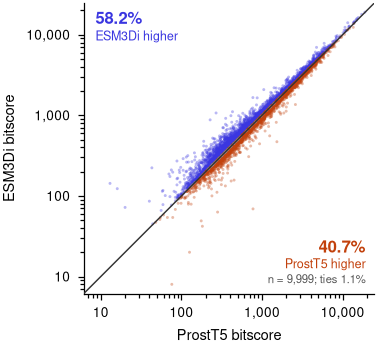

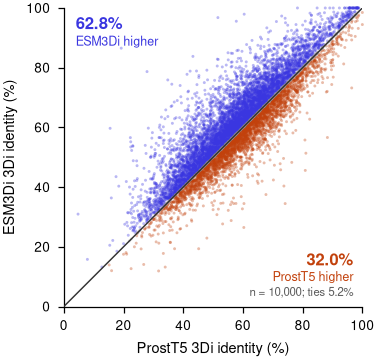

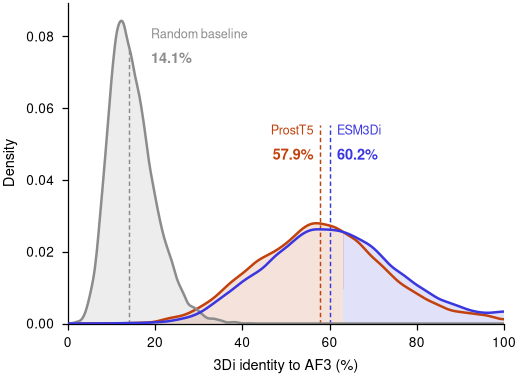

In [18]:
DENSITY_TITLE = "Identity distribution"

# Bitscore comparison (bitscores span orders of magnitude, so log axes)
fig, ax = plt.subplots(figsize=(65 * MM, 65 * MM), layout="constrained")
plot_method_scatter(ax, df_benchmark, **BITSCORE_ARGS)
save_pub(fig, "3di_bitscore_scatter", FIG_DIR) 
plt.show()

# 3Di identity comparison
fig, ax = plt.subplots(figsize=(65 * MM, 65 * MM), layout="constrained")
plot_method_scatter(ax, df_benchmark, **IDENTITY_ARGS)
save_pub(fig, "3di_identity_scatter", FIG_DIR)
plt.show()

# 3Di identity distributions
fig, ax = plt.subplots(figsize=(89 * MM, 65 * MM), layout="constrained")
plot_identity_density(ax, df_benchmark)#, title=DENSITY_TITLE)
save_pub(fig, "3di_identity_density", FIG_DIR)
plt.show()

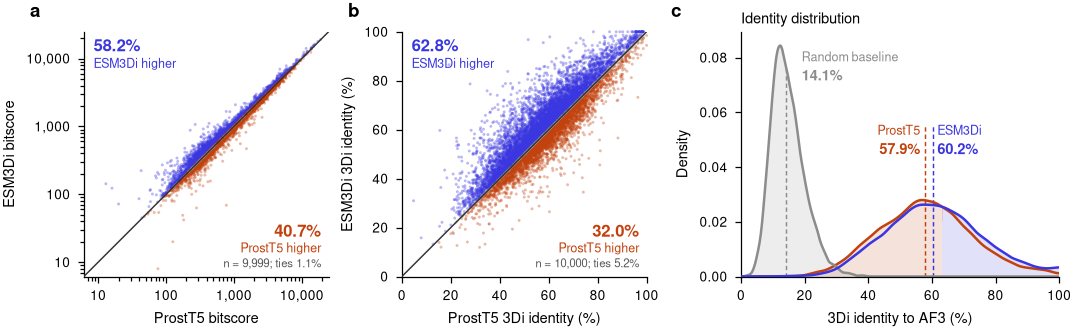

In [19]:
# Combined figure (full page width): a) bitscore, b) identity, c) identity distributions
fig, axes = plt.subplots(
    1, 3, figsize=(WIDTH_DOUBLE, 64 * MM), layout="constrained",
    gridspec_kw={"width_ratios": [1, 1, 1.3]},
)
plot_method_scatter(axes[0], df_benchmark, **BITSCORE_ARGS)
plot_method_scatter(axes[1], df_benchmark, **IDENTITY_ARGS)
plot_identity_density(axes[2], df_benchmark, title=DENSITY_TITLE)
axes[2].set_box_aspect(1 / 1.3)  # same height as the square scatter panels
add_panel_labels(axes)
save_pub(fig, "3di_alignment_combined", FIG_DIR)
plt.show()

In [20]:
# Per-protein results, also used by the assembled figures (../../paper/figure1.ipynb)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
df_benchmark.to_csv(RESULTS_DIR / "3di_benchmark.csv", index=False)